<a href="https://colab.research.google.com/github/AndresMontesDeOca/vision_computadora_II/blob/VpC2_2026/CS_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# !pip install roboflow ultralytics

import os
import yaml
import json
import random
import cv2
import matplotlib.pyplot as plt
from google.colab import userdata
from roboflow import Roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 20.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [3]:


# Ruta esperada del dataset
dataset_path = '/content/Counter-Strike-1'

# Verificar si el dataset ya existe en el entorno
if not os.path.exists(dataset_path):
    print("El dataset no fue detectado. Iniciando descarga desde Roboflow...")
    # Obtener la clave API de Roboflow de los secretos de Colab de manera segura
    api_key = userdata.get("ROBOFLOW_API_KEY")
    rf = Roboflow(api_key=api_key)

    # Descarga del dataset en formato YOLOv11
    project = rf.workspace("counter-strike-uovxc").project("counter-strike-h9y80")
    version = project.version(1)
    dataset = version.download("yolov11")
else:
    print(f"El dataset ya existe en '{dataset_path}'. Se omitió la descarga para optimizar tiempo.")

El dataset no fue detectado. Iniciando descarga desde Roboflow...
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Counter-Strike-1 in yolov11:: 100%|██████████| 7374/7374 [00:02<00:00, 2853.61it/s]


In [4]:
import os
import glob
import yaml
import json

# Cargar y mostrar la configuración de clases y rutas
data_yaml_path = '/content/Counter-Strike-1/data.yaml'
with open(data_yaml_path, 'r') as file:
    dataset_info = yaml.safe_load(file)

print("Estructura y clases del dataset:")
print(json.dumps(dataset_info, indent=4))
print("\n" + "="*40 + "\n")

# Contar imágenes en cada carpeta del dataset
# Roboflow descarga todo dentro de '/content/Counter-Strike-1'
# Si la ruta es '../train/images', queremos buscar dentro de '/content/Counter-Strike-1/train/images'
dataset_root = '/content/Counter-Strike-1'

for split in ['train', 'val', 'test']:
    yaml_key = split
    if split == 'val' and 'val' not in dataset_info and 'valid' in dataset_info:
        yaml_key = 'valid'

    if yaml_key in dataset_info:
        # Limpiamos la ruta relativa eliminando '../' inicial para buscar directamente dentro del directorio descargado
        split_path = dataset_info[yaml_key].lstrip('./').replace('../', '')
        full_split_path = os.path.abspath(os.path.join(dataset_root, split_path))

        # Buscar extensiones de imágenes
        image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.JPG', '*.JPEG', '*.PNG')
        images_found = []
        for ext in image_extensions:
            images_found.extend(glob.glob(os.path.join(full_split_path, ext)))

        print(f"Carpeta '{split}': {len(images_found)} imágenes encontradas en {full_split_path}")
    else:
        print(f"No se encontró la definición de '{split}' o '{yaml_key}' en data.yaml")

Estructura y clases del dataset:
{
    "train": "../train/images",
    "val": "../valid/images",
    "test": "../test/images",
    "nc": 2,
    "names": [
        "ct",
        "t"
    ],
    "roboflow": {
        "workspace": "counter-strike-uovxc",
        "project": "counter-strike-h9y80",
        "version": 1,
        "license": "CC BY 4.0",
        "url": "https://universe.roboflow.com/counter-strike-uovxc/counter-strike-h9y80/dataset/1"
    }
}


Carpeta 'train': 2577 imágenes encontradas en /content/Counter-Strike-1/train/images
Carpeta 'val': 736 imágenes encontradas en /content/Counter-Strike-1/valid/images
Carpeta 'test': 368 imágenes encontradas en /content/Counter-Strike-1/test/images


In [5]:
def plot_yolo_sample(img_path, lbl_path, class_names):
    """Dibuja cajas YOLO en una imagen usando azul para CT y rojo para Terroristas."""
    if not os.path.exists(img_path):
        print(f"No se encontró la imagen: {img_path}")
        return

    # Cargar y convertir imagen
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    # Colores en RGB: Azul para clase 0 (ct), Rojo para clase 1 (t)
    colors = [(0, 0, 255), (255, 0, 0)]

    if os.path.exists(lbl_path):
        with open(lbl_path, 'r') as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id = int(parts[0])
                x_center, y_center, bbox_w, bbox_h = map(float, parts[1:])

                # Convertir coordenadas YOLO normalizadas a píxeles
                x1 = int((x_center - bbox_w / 2) * w)
                y1 = int((y_center - bbox_h / 2) * h)
                x2 = int((x_center + bbox_w / 2) * w)
                y2 = int((y_center + bbox_h / 2) * h)

                # Dibujar rectángulo y texto informativo
                color = colors[cls_id % len(colors)]
                cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

                label = class_names[cls_id] if cls_id < len(class_names) else str(cls_id)
                cv2.putText(image, label, (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

In [6]:
def plot_random_samples(images_dir, labels_dir, class_names, num_samples=3):
    """Selecciona de manera aleatoria 'num_samples' imágenes y las renderiza con sus etiquetas."""
    if not os.path.exists(images_dir) or not os.path.exists(labels_dir):
        print("No se encontraron las carpetas de imágenes o etiquetas.")
        return

    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if len(all_images) < num_samples:
        print(f"No hay suficientes imágenes disponibles (Encontradas: {len(all_images)}).")
        return

    selected_images = random.sample(all_images, num_samples)

    for img_name in selected_images:
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        img_path = os.path.join(images_dir, img_name)
        lbl_path = os.path.join(labels_dir, lbl_name)

        print(f"Mostrando muestra aleatoria: {img_name}")
        plot_yolo_sample(img_path, lbl_path, class_names)

Mostrando muestra aleatoria: csdata_311-4-_png.rf.914b8dfc01c0ef241ae92507035dce0b.jpg


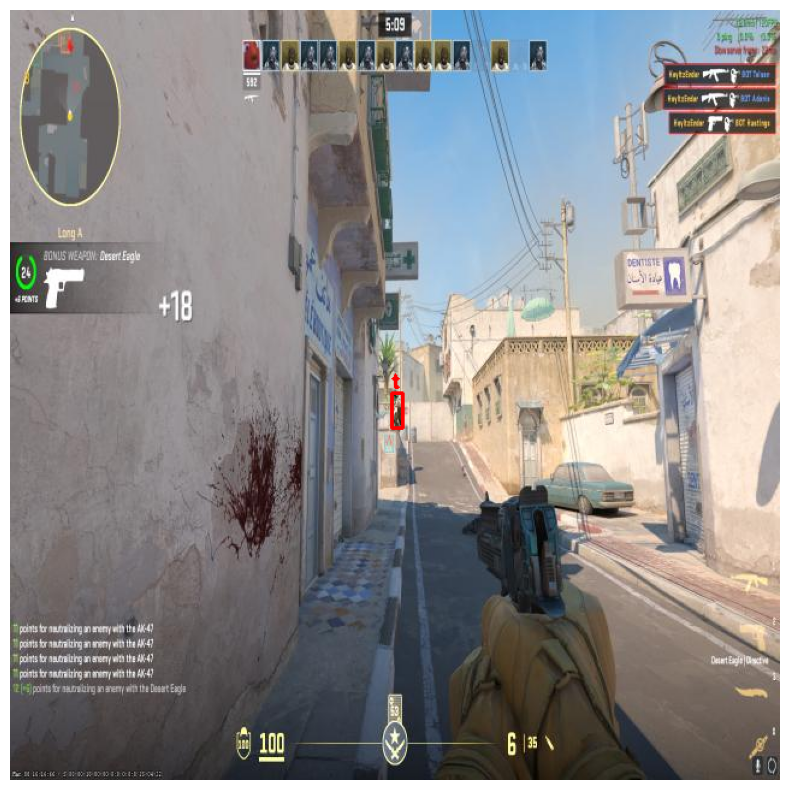

Mostrando muestra aleatoria: csdata_291-4-_png.rf.00e0a6e3122d1490302a1c06037871a1.jpg


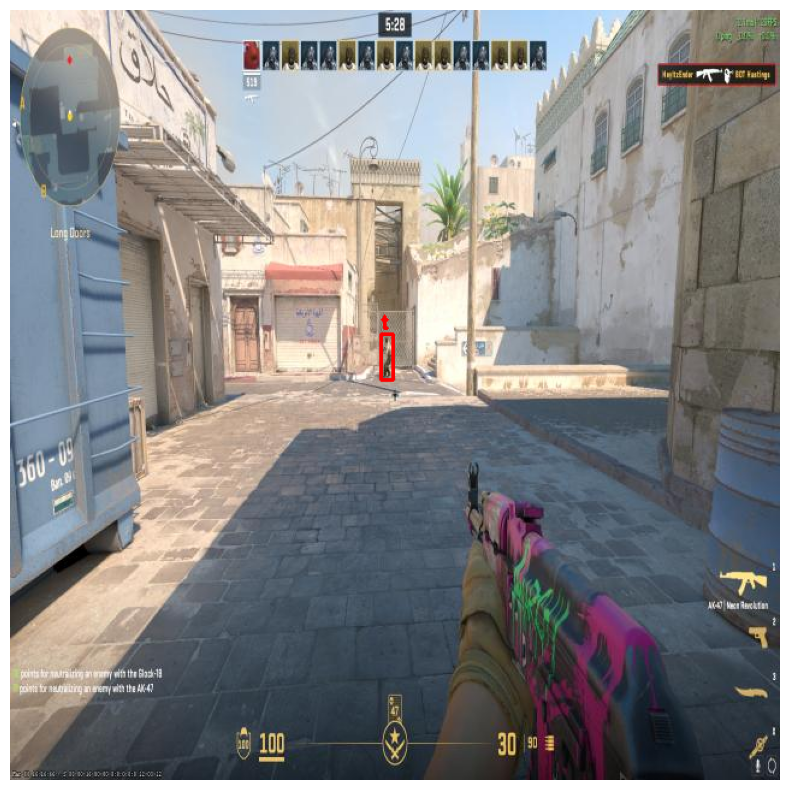

Mostrando muestra aleatoria: csdata_352-2-_png.rf.20bbae0d99f4f85cef3070bf4f5f73dc.jpg


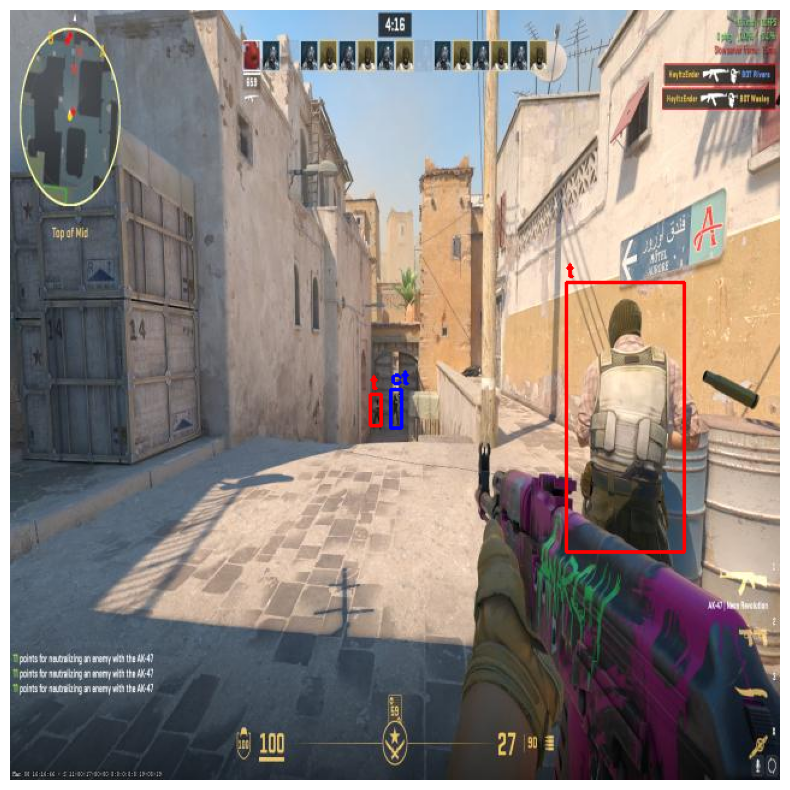

In [7]:
# Definición de rutas principales
images_dir = '/content/Counter-Strike-1/train/images'
labels_dir = '/content/Counter-Strike-1/train/labels'
class_names = dataset_info.get('names', ['ct', 't'])

# Ejecutar visualización de 3 imágenes al azar
plot_random_samples(images_dir, labels_dir, class_names, num_samples=3)

Conteo de formatos de archivos encontrados:
Formato
.jpg    2577
Name: count, dtype: int64


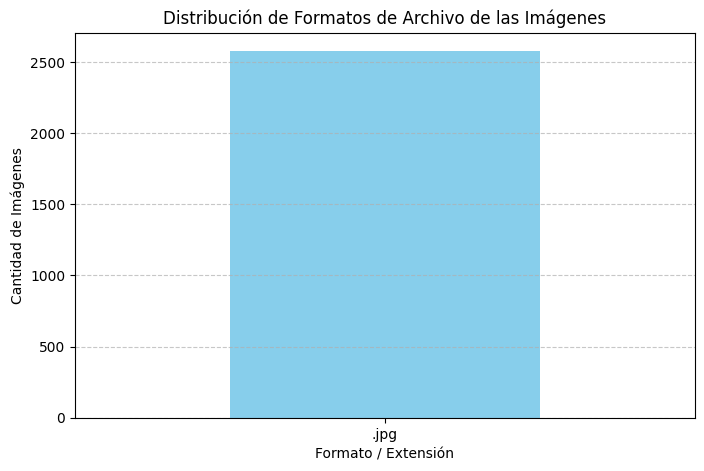

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Obtener lista de todos los archivos en la carpeta de imágenes
if os.path.exists(images_dir):
    files = os.listdir(images_dir)
    # Extraer la extensión de cada archivo y convertirla a minúsculas
    extensions = [os.path.splitext(f)[1].lower() for f in files if os.path.isfile(os.path.join(images_dir, f))]

    # Crear un contador con Pandas
    df_ext = pd.DataFrame(extensions, columns=['Formato'])
    conteo = df_ext['Formato'].value_counts()

    # Mostrar el conteo en texto
    print("Conteo de formatos de archivos encontrados:")
    print(conteo)

    # Crear gráfico de barras
    plt.figure(figsize=(8, 5))
    conteo.plot(kind='bar', color=['skyblue', 'salmon', 'lightgreen', 'orange'])
    plt.title('Distribución de Formatos de Archivo de las Imágenes')
    plt.xlabel('Formato / Extensión')
    plt.ylabel('Cantidad de Imágenes')
    plt.xticks(rotation=0)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()
else:
    print(f"No se encontró la ruta de imágenes especificada: {images_dir}")

Frecuencia de clases por partición:


,Train,Valid,Test
Counter-Terrorist (ct),1778,522,246
Terrorist (t),1664,476,233


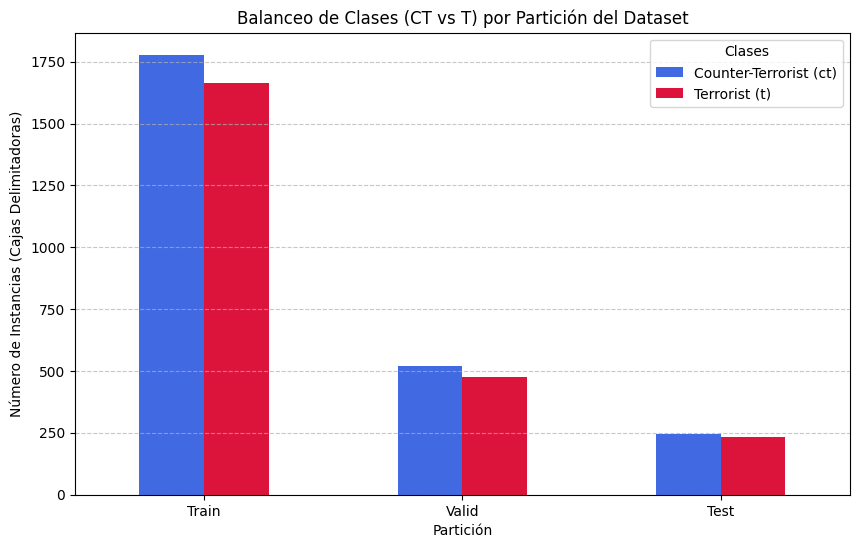

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def contar_clases_en_particion(labels_dir_path):
    counts = {0: 0, 1: 0}
    if not os.path.exists(labels_dir_path):
        return counts

    for label_file in os.listdir(labels_dir_path):
        if label_file.endswith('.txt'):
            with open(os.path.join(labels_dir_path, label_file), 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if parts:
                        try:
                            cls_id = int(parts[0])
                            if cls_id in counts:
                                counts[cls_id] += 1
                        except ValueError:
                            continue
    return counts

# Rutas de las carpetas de etiquetas
particiones = {
    'Train': '/content/Counter-Strike-1/train/labels',
    'Valid': '/content/Counter-Strike-1/valid/labels',
    'Test': '/content/Counter-Strike-1/test/labels'
}

resultados = {}
for nombre, ruta in particiones.items():
    resultados[nombre] = contar_clases_en_particion(ruta)

# Crear un DataFrame para facilitar la graficación
df_balance = pd.DataFrame(resultados).rename(index={0: 'Counter-Terrorist (ct)', 1: 'Terrorist (t)'})

print("Frecuencia de clases por partición:")
display(df_balance)

# Graficar los resultados
fig, ax = plt.subplots(figsize=(10, 6))
df_balance.T.plot(kind='bar', ax=ax, color=['royalblue', 'crimson'])
plt.title('Balanceo de Clases (CT vs T) por Partición del Dataset')
plt.xlabel('Partición')
plt.ylabel('Número de Instancias (Cajas Delimitadoras)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Clases')
plt.show()

Resumen de las dimensiones y canales de las imágenes:


,Ancho,Alto,Canales,Aspect_Ratio
count,2577.0,2577.0,2577.0,2577.0
mean,640.0,640.0,3.0,1.0
std,0.0,0.0,0.0,0.0
min,640.0,640.0,3.0,1.0
25%,640.0,640.0,3.0,1.0
50%,640.0,640.0,3.0,1.0
75%,640.0,640.0,3.0,1.0
max,640.0,640.0,3.0,1.0


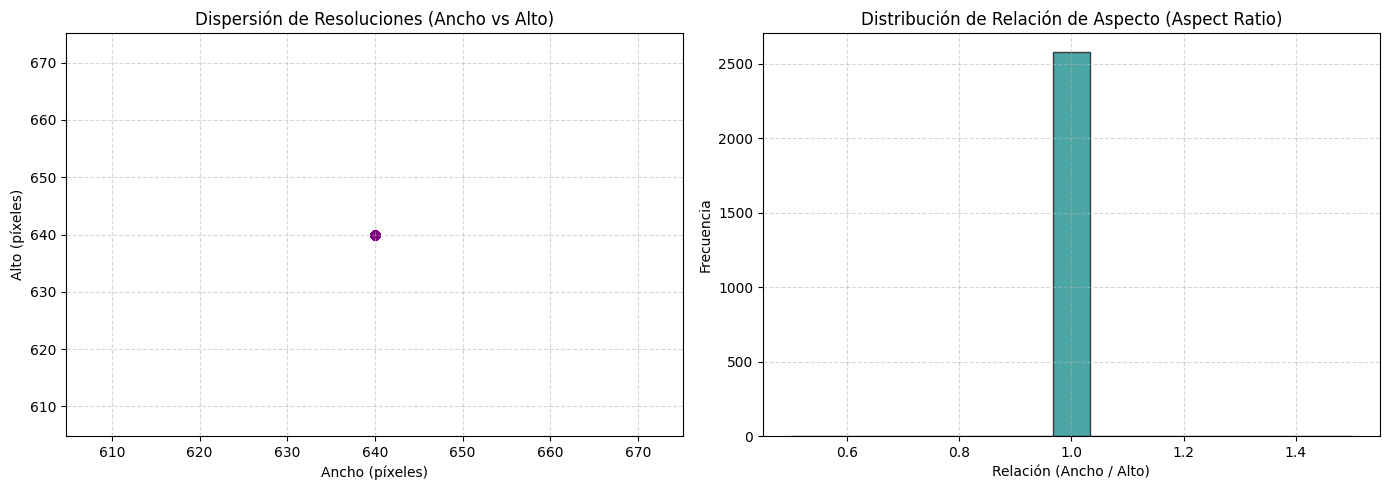

In [10]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

resoluciones = []

if os.path.exists(images_dir):
    all_images = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    for img_name in all_images:
        img_path = os.path.join(images_dir, img_name)
        # Leer de forma rápida la imagen
        img = cv2.imread(img_path)
        if img is not None:
            h, w, c = img.shape
            aspect_ratio = w / h
            resoluciones.append({'Ancho': w, 'Alto': h, 'Canales': c, 'Aspect_Ratio': aspect_ratio})

    df_dims = pd.DataFrame(resoluciones)

    # Resumen estadístico
    print("Resumen de las dimensiones y canales de las imágenes:")
    display(df_dims.describe())

    # Crear gráficos de distribución
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Gráfico de dispersión de resoluciones (Ancho vs Alto)
    axes[0].scatter(df_dims['Ancho'], df_dims['Alto'], alpha=0.5, color='purple')
    axes[0].set_title('Dispersión de Resoluciones (Ancho vs Alto)')
    axes[0].set_xlabel('Ancho (píxeles)')
    axes[0].set_ylabel('Alto (píxeles)')
    axes[0].grid(True, linestyle='--', alpha=0.5)

    # Histograma de Relación de Aspecto
    axes[1].hist(df_dims['Aspect_Ratio'], bins=15, color='teal', edgecolor='black', alpha=0.7)
    axes[1].set_title('Distribución de Relación de Aspecto (Aspect Ratio)')
    axes[1].set_xlabel('Relación (Ancho / Alto)')
    axes[1].set_ylabel('Frecuencia')
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()
else:
    print("No se pudo acceder al directorio de imágenes de entrenamiento.")

## Entrenamiento

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    project="runs",
    name="cs_v2",
    exist_ok=True
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Counter-Strike-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

In [ ]:
metrics = model.val(
    imgsz=640,
    project="runs",
    name="cs_v2_VAL",
    exist_ok=True,
    plots=True
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precisión por clase:", metrics.box.maps)
